### Causal Forest, Double ML and Propensity Score Matching

In this notebook I try three more methods on the same 5% sample from `Modeling_sample_2.ipynb`. I use the same train / validation / test split and the same metrics, so I can compare the results directly.

- **Propensity score matching (PSM)** gives one number: the average effect of the campaign. It can't rank customers, so I only compare it with the other average effect estimates.
- **Double ML** gives the average effect, and also a predicted effect for each customer.
- **Causal forest** gives a predicted effect for each customer.
- Double ML and the causal forest can rank customers, so I compare them with the baseline using Qini AUC and uplift in the top 5% to 50%.
- Like in the rest of the project, treatment means being **assigned** to the campaign, not actually seeing the ad. So the matching here is between the treatment and control groups (not on exposure).

- I need the `econml` package for the causal forest.

In [1]:
!pip install econml

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import time

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import auc, roc_auc_score
from econml.grf import CausalForest

### Data and Split

- I use the same split as in `Modeling_sample_2.ipynb`: 60% train, 20% validation and 20% test, stratified by treatment and conversion together, with the same `random_state`. So the test set has the same customers.

In [3]:
sample = pd.read_parquet('criteo_sample_5pct.parquet').reset_index(drop=True)

feature_cols = [f'f{i}' for i in range(12)]

X = sample[feature_cols]
T = sample['treatment']
y = sample['conversion']

# treatment and conversion together (0 = control/no, 1 = control/yes, 2 = treated/no, 3 = treated/yes)
strata = T * 2 + y

print('Customers:', len(sample))
print('Share in the treatment group:', T.mean())
strata.value_counts().sort_index()

Customers: 698980
Share in the treatment group: 0.85


0    104636
1       211
2    592263
3      1870
Name: count, dtype: int64

In [4]:
# 60% train, 40% left over
X_train, X_temp, T_train, T_temp, y_train, y_temp = train_test_split(
    X, T, y,
    test_size=0.4,
    random_state=42,
    stratify=strata
)

# split the 40% left over 50/50 into validation and test
X_val, X_test, T_val, T_test, y_val, y_test = train_test_split(
    X_temp, T_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=strata.loc[X_temp.index]
)

print('Train size:', len(X_train))
print('Validation size:', len(X_val))
print('Test size:', len(X_test))
print('Control conversions in train, validation and test:',
      y_train[T_train == 0].sum(), y_val[T_val == 0].sum(), y_test[T_test == 0].sum())

Train size: 419388
Validation size: 139796
Test size: 139796
Control conversions in train, validation and test: 127 42 42


### Functions

- These are the functions I use to train and evaluate the models. They're the same as in my modeling notebook.
- `evaluate_model` gives the Qini AUC and the uplift in the top 5% to 50%.
- For the bootstrap, I draw each resample once and use it for every model, so the comparison is fair.

In [5]:
def train_gb(X, y):
    # best settings from the tuning in Modeling_sample_2.ipynb
    model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=500,
        min_samples_leaf=100,
        max_leaf_nodes=31,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42
    )
    model.fit(X, y)
    return model


def smd(df, cols):
    # standardized mean difference between treatment and control
    treated = df[df['treatment'] == 1][cols]
    control = df[df['treatment'] == 0][cols]
    pooled_std = np.sqrt((treated.var() + control.var()) / 2)
    return (treated.mean() - control.mean()) / pooled_std

In [6]:
def uplift_curve(df, score_col):
    # shuffle first so customers with the same score are in random order, then sort by score
    df = df.sample(frac=1, random_state=42)
    df = df.sort_values(score_col, ascending=False, kind='stable')

    treated = (df['treatment'] == 1).astype(int)
    control = (df['treatment'] == 0).astype(int)
    conv = df['conversion'].astype(int)

    # running totals going down the list
    n_treated = treated.cumsum()
    n_control = control.cumsum()
    conv_treated = (conv * treated).cumsum()
    conv_control = (conv * control).cumsum()

    curve = pd.DataFrame()
    curve['pct_targeted'] = np.arange(1, len(df) + 1) / len(df)
    curve['qini'] = (conv_treated - conv_control * n_treated / n_control.clip(lower=1)).values

    return curve

In [7]:
def get_metrics(treatment, conversion, score):
    # the arrays need to be shuffled already, so ties are broken at random
    n = len(score)

    # sort from highest to lowest score
    order = np.argsort(-score, kind='stable')
    treated = treatment[order].astype(np.int64)
    conv = conversion[order].astype(np.int64)
    control = 1 - treated

    n_treated = np.cumsum(treated)
    n_control = np.cumsum(control)
    conv_treated = np.cumsum(conv * treated)
    conv_control = np.cumsum(conv * control)

    # Qini curve and the area between it and the random line
    qini = conv_treated - conv_control * n_treated / np.maximum(n_control, 1)
    pct = np.arange(1, n + 1) / n
    gain = (qini - pct * qini[-1]) / n

    metrics = {'qini_auc': auc(pct, gain)}

    # uplift in the top k%
    for k in [5, 10, 20, 30, 50]:
        i = int(n * k / 100) - 1
        if n_treated[i] == 0 or n_control[i] == 0:
            metrics[f'uplift@{k}%'] = 0.0
        else:
            metrics[f'uplift@{k}%'] = conv_treated[i] / n_treated[i] - conv_control[i] / n_control[i]

    return metrics


def evaluate_model(df, score_col):
    # shuffle once so tied scores are in random order
    order = np.random.default_rng(42).permutation(len(df))

    t = df['treatment'].to_numpy()[order]
    c = df['conversion'].to_numpy()[order]
    s = df[score_col].to_numpy()[order]

    return get_metrics(t, c, s)

In [8]:
def bootstrap(df, model_cols, n_resamples=200):
    n = len(df)
    t = df['treatment'].to_numpy()
    c = df['conversion'].to_numpy()

    boot = {}
    for col in model_cols:
        boot[col] = []

    for i in range(n_resamples):
        # draw n customers with replacement, same rows for every model
        rows = np.random.default_rng(i).integers(0, n, size=n)

        for col in model_cols:
            s = df[col].to_numpy()
            boot[col].append(get_metrics(t[rows], c[rows], s[rows]))

    # one table per model, one row per resample
    for col in model_cols:
        boot[col] = pd.DataFrame(boot[col])

    return boot


def ci_table(df, model_cols, boot):
    # estimate and 95% interval for each model
    table = {}
    for col in model_cols:
        est = evaluate_model(df, col)
        row = {}
        for m in est:
            low = boot[col][m].quantile(0.025)
            high = boot[col][m].quantile(0.975)
            row[m] = f'{est[m]:.4f} [{low:.4f}, {high:.4f}]'
        table[col] = row
    return pd.DataFrame(table).T


def diff_table(df, model_cols, boot):
    # difference between each model and the baseline, with a 95% interval
    base = evaluate_model(df, 'baseline')
    table = {}
    for col in model_cols:
        if col == 'baseline':
            continue
        est = evaluate_model(df, col)
        diffs = boot[col] - boot['baseline']
        row = {}
        for m in est:
            low = diffs[m].quantile(0.025)
            high = diffs[m].quantile(0.975)
            row[m] = f'{est[m] - base[m]:.4f} [{low:.4f}, {high:.4f}]'
        table[col] = row
    return pd.DataFrame(table).T

### Baseline

- I retrain the baseline Gradient Boosting model from `Modeling_sample_2.ipynb` (same settings), so I can compare everything in this notebook.
- **Baseline:** ranks customers by how likely they are to convert if treated.
- The T-learner and the other meta-learners (S-learner, X-learner) are compared in `Modeling_sample_2.ipynb`, so I don't repeat them here.
- The baseline numbers below should be the same as in `Modeling_sample_2.ipynb`. If they're not, the file or the split is different.

In [9]:
gb_treated = train_gb(X_train[T_train == 1], y_train[T_train == 1])

val_results = pd.DataFrame({
    'treatment': T_val.to_numpy(),
    'conversion': y_val.to_numpy()
})

results = pd.DataFrame({
    'treatment': T_test.to_numpy(),
    'conversion': y_test.to_numpy(),
    'baseline': gb_treated.predict_proba(X_test)[:, 1]
})

pd.Series(evaluate_model(results, 'baseline'))

qini_auc      0.000368
uplift@5%     0.009284
uplift@10%    0.008029
uplift@20%    0.004650
uplift@30%    0.003195
uplift@50%    0.002187
dtype: float64

### Propensity Scores

- PSM and Double ML both need the **propensity**: the probability that a customer is in the treatment group, given the features.
- Since the experiment is randomized, the propensity should be about 0.85 for everyone, and the features shouldn't be able to predict treatment.
- Double ML also needs a prediction of conversion from the features only (without treatment), so I get both in the same function.
- **Cross-fitting:** I split the data into 5 folds. Each customer's predictions come from models trained on the other 4 folds, so no customer is predicted by a model that saw their own outcome.

In [10]:
def cross_fit(X, T, y):
    y_pred = np.zeros(len(X))
    t_pred = np.zeros(len(X))

    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for train_idx, pred_idx in folds.split(X, T * 2 + y):

        # predict conversion from the features
        y_model = train_gb(X.iloc[train_idx], y.iloc[train_idx])
        y_pred[pred_idx] = y_model.predict_proba(X.iloc[pred_idx])[:, 1]

        # predict treatment from the features
        t_model = train_gb(X.iloc[train_idx], T.iloc[train_idx])
        t_pred[pred_idx] = t_model.predict_proba(X.iloc[pred_idx])[:, 1]

    return y_pred, t_pred

In [11]:
start = time.time()

# all customers (used for the average effect)
y_pred_all, propensity_all = cross_fit(X, T, y)

print('Minutes:', round((time.time() - start) / 60, 1))
print('Treatment AUC (0.5 = features cannot predict treatment):', roc_auc_score(T, propensity_all))
print('Conversion AUC:', roc_auc_score(y, y_pred_all))

pd.Series(propensity_all).describe()

Minutes: 1.9
Treatment AUC (0.5 = features cannot predict treatment): 0.5094733711249069
Conversion AUC: 0.9554192637053456


count    698980.000000
mean          0.850004
std           0.009387
min           0.741850
25%           0.846533
50%           0.848857
75%           0.849250
max           0.960722
dtype: float64

- Below I plot the propensity for both groups on the log-odds scale. Matching only works where the two groups overlap.

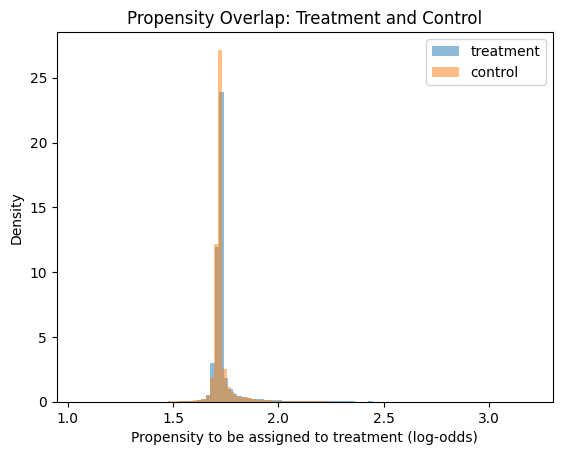

In [12]:
psm_data = sample[feature_cols + ['treatment', 'conversion']].copy()

p = np.clip(propensity_all, 0.01, 0.99)
psm_data['propensity'] = p
psm_data['logit'] = np.log(p / (1 - p))

treated = psm_data[psm_data['treatment'] == 1]
control = psm_data[psm_data['treatment'] == 0]

plt.hist(treated['logit'], bins=100, density=True, alpha=0.5, label='treatment')
plt.hist(control['logit'], bins=100, density=True, alpha=0.5, label='control')
plt.xlabel('Propensity to be assigned to treatment (log-odds)')
plt.ylabel('Density')
plt.title('Propensity Overlap: Treatment and Control')
plt.legend()
plt.show()

**Result:**

- **Treatment AUC = 0.509**, which is very close to 0.5. So the features can barely predict who was put in the treatment group, which means the randomization mostly worked.
- The propensities are all very close to 0.85 (std = 0.009, and 50% of customers are between 0.847 and 0.849).
- In the plot, the treatment and control distributions sit on top of each other, so there is full overlap and every control customer should be able to find a match.
- **Conversion AUC = 0.955**, so the features predict conversion very well. This is useful for Double ML, because taking out the predictable part of conversion removes a lot of noise.

### Propensity Score Matching

- For each **control** customer, I find the treated customer with the closest propensity (1 nearest neighbor, on the log-odds scale). I match in this direction because there are about 6 treated customers for every control customer.
- Matching is **with replacement**, so one treated customer can be matched to more than one control customer.
- **Caliper:** if the closest match is more than 0.2 standard deviations of the log-odds away, I drop that control customer.
- **Ties:** a lot of customers have exactly the same propensity, so they would all be matched to the same treated customer. To avoid this, I add a tiny random number to each log-odds value so ties are broken at random.

In [13]:
caliper = 0.2 * psm_data['logit'].std()

# tiny random noise (much smaller than the caliper) to break ties
rng = np.random.default_rng(42)
treated_logit = treated[['logit']].to_numpy() + rng.uniform(-1e-6, 1e-6, size=(len(treated), 1))
control_logit = control[['logit']].to_numpy() + rng.uniform(-1e-6, 1e-6, size=(len(control), 1))

nn = NearestNeighbors(n_neighbors=1)
nn.fit(treated_logit)

distance, index = nn.kneighbors(control_logit)
distance = distance[:, 0]
index = index[:, 0]

keep = distance <= caliper

matched_control = control[keep]
matched_treated = treated.iloc[index[keep]]

# how many times each treated customer was used
times_used = matched_treated.index.value_counts()

print('Control customers:', len(control))
print('Share matched within the caliper:', keep.mean())
print('Different treated customers used:', len(times_used))
print('Most times one treated customer was used:', times_used.max())

Control customers: 104847
Share matched within the caliper: 1.0
Different treated customers used: 92364
Most times one treated customer was used: 5


**Balance after matching**

- I check the standardized mean differences (SMD) between treatment and control before and after matching. Below 0.1 is usually considered balanced.
- The SMDs were already small before matching because the experiment is randomized. So I also check two harder things: the SMD of the **predicted conversion probability**, and the share of each group in the top 10% of predicted conversion.

In [14]:
psm_data['outcome_prediction'] = y_pred_all

cutoff = psm_data['outcome_prediction'].quantile(0.9)
psm_data['top_10'] = (psm_data['outcome_prediction'] >= cutoff).astype(int)

cols = feature_cols + ['outcome_prediction']

matched = pd.concat([psm_data.loc[matched_treated.index], psm_data.loc[matched_control.index]])

balance = pd.DataFrame({
    'before matching': smd(psm_data, cols),
    'after matching': smd(matched, cols)
})

print('Largest absolute SMD before matching:', balance['before matching'].abs().max())
print('Largest absolute SMD after matching:', balance['after matching'].abs().max())
print()
print('Share in the top 10% by predicted conversion')
print('  Before matching: treatment', psm_data[psm_data['treatment'] == 1]['top_10'].mean(),
      '| control', psm_data[psm_data['treatment'] == 0]['top_10'].mean())
print('  After matching:  treatment', psm_data.loc[matched_treated.index, 'top_10'].mean(),
      '| control', psm_data.loc[matched_control.index, 'top_10'].mean())

balance.round(4)

Largest absolute SMD before matching: 0.052859136377491144
Largest absolute SMD after matching: 0.010639609965068794

Share in the top 10% by predicted conversion
  Before matching: treatment 0.10138470679124034 | control 0.0921724035976232
  After matching:  treatment 0.09064637042547713 | control 0.0921724035976232


,before matching,after matching
f0,-0.0056,-0.0009
f1,0.0228,0.0012
f2,-0.0114,-0.0043
f3,-0.0529,-0.0005
f4,0.0091,-0.0106
f5,-0.0303,0.0054
f6,-0.0404,0.0038
f7,0.0231,-0.0066
f8,-0.0199,0.0080
f9,0.0252,-0.0043


**Result:**

- All 104,847 control customers found a match within the caliper (share matched = 1.0), so no one was dropped. This makes sense since the overlap was complete.
- 92,364 different treated customers were used, and no treated customer was used more than 5 times. So the matches aren't relying on just a few customers.
- **Feature balance:** the largest SMD went down from 0.053 (f3) before matching to 0.011 after matching. All features were already below 0.1 before matching, so the groups were already balanced, but matching made them even closer.
- **Top 10% by predicted conversion:** before matching, 10.1% of the treated group was in the top 10% vs 9.2% of the control group. So the treated group had slightly more customers who were likely to convert anyway. After matching it's 9.1% vs 9.2%, so this small difference is gone.

### Average Effect: Three Estimates

1. **Raw difference:** treatment conversion rate minus control conversion rate. This relies on the randomization only. It is the effect of being targeted (ITT) that `Modeling_sample_2.ipynb` uses as its randomized comparison.
2. **Matched:** conversion rate of the matched treated customers minus their matched control customers.
3. **Double ML:** I take out the part of conversion and of treatment that the features can predict, and then regress what's left of conversion on what's left of treatment:

   `conversion − predicted conversion = effect × (treatment − propensity) + error`

   This is like partialling out controls in a regression (Frisch–Waugh–Lovell), but with Gradient Boosting. I use robust (HC1) standard errors.

- If the randomization worked, all three should be close. If treated customers were a bit more likely to convert anyway, the matched and Double ML estimates should be lower than the raw difference.
- The standard error of the matched estimate is only approximate. It accounts for treated customers being used more than once, but not for the propensity being estimated.

In [15]:
# 1. Raw difference
p_t = treated['conversion'].mean()
p_c = control['conversion'].mean()

raw_effect = p_t - p_c
raw_se = np.sqrt(p_t * (1 - p_t) / len(treated) + p_c * (1 - p_c) / len(control))

# 2. Matched
p_mt = matched_treated['conversion'].mean()
p_mc = matched_control['conversion'].mean()

matched_effect = p_mt - p_mc

# a treated customer used k times counts k times, so the SE has to be bigger
n_pairs = len(matched_control)
matched_se = np.sqrt(
    p_mc * (1 - p_mc) / n_pairs
    + p_mt * (1 - p_mt) * (times_used ** 2).sum() / n_pairs ** 2
)

# 3. Double ML
y_resid_all = y.to_numpy() - y_pred_all
t_resid_all = T.to_numpy() - np.clip(propensity_all, 0.01, 0.99)

dml = sm.OLS(y_resid_all, t_resid_all).fit(cov_type='HC1')

dml_effect = dml.params[0]
dml_se = dml.bse[0]

ate = pd.DataFrame({
    'effect': [raw_effect, matched_effect, dml_effect],
    'standard error': [raw_se, matched_se, dml_se]
}, index=['raw difference', 'matched', 'double ML'])

ate['lower 95%'] = ate['effect'] - 1.96 * ate['standard error']
ate['upper 95%'] = ate['effect'] + 1.96 * ate['standard error']

# in percentage points
(ate * 100).round(4)

,effect,standard error,lower 95%,upper 95%
raw difference,0.1135,0.0156,0.0829,0.1441
matched,0.0906,0.0233,0.0449,0.1363
double ML,0.0810,0.0150,0.0515,0.1104


**Result:**

- All three estimates are positive and none of the 95% intervals include 0, so being assigned to the campaign clearly increases conversion.
- **Raw difference:** 0.114 pp, 95% CI [0.083, 0.144], about a 56% relative lift
- **Matched:** 0.091 pp, 95% CI [0.045, 0.136], about a 45% relative lift
- **Double ML:** 0.081 pp, 95% CI [0.052, 0.110], about a 40% relative lift
- The relative lift is the effect divided by the control conversion rate (0.20%).
- The matched and Double ML estimates are **lower** than the raw difference. This matches what I saw above: the treated group had slightly more customers who would convert anyway, so the raw difference gives the campaign a bit too much credit.
- But the intervals overlap a lot, so the difference between the three estimates could also just be noise. (`Causal_Forest_DML_PSM_full.ipynb` shows that the gap is real: with the full data, the raw difference overstates the effect by about 0.03 pp.)
- Double ML has the narrowest interval (SE = 0.015 pp), because removing the predictable part of conversion takes out a lot of noise. The matched estimate has the widest interval (SE = 0.023 pp), because it only uses the matched customers and some treated customers are used more than once.
- So my best estimate is that the campaign increases conversion by about **0.08 to 0.11 percentage points**, or roughly a **40-55% relative lift**.

### Double ML: Effect for Each Customer

- To rank customers, the effect has to depend on the features. So I keep the same idea as above, but let the effect be a **linear function of the features**:

  `conversion − predicted conversion = (a + b1 × f0 + ... + b12 × f11) × (treatment − propensity) + error`

- The predicted effect for a customer is then `a + b1 × f0 + ... + b12 × f11`.
- From here on I only train on the **training set**, like in `Modeling_sample_2.ipynb`. So I redo the cross-fitting on the training set only.
- I standardize the features with the training means and standard deviations, so the coefficients can be compared. Each coefficient is the change in the effect for a 1 std increase in that feature.

In [16]:
start = time.time()

y_pred_train, propensity_train = cross_fit(X_train, T_train, y_train)

y_resid = y_train.to_numpy() - y_pred_train
t_resid = T_train.to_numpy() - np.clip(propensity_train, 0.01, 0.99)

print('Minutes:', round((time.time() - start) / 60, 1))

Minutes: 1.3


In [17]:
train_mean = X_train.mean()
train_std = X_train.std()


def make_regressors(X):
    # a constant plus the standardized features
    X_std = (X - train_mean) / train_std
    return sm.add_constant(X_std, has_constant='add')


# multiply each regressor by the treatment residual
X_dml = make_regressors(X_train).mul(t_resid, axis=0)

dml_linear = sm.OLS(y_resid, X_dml).fit(cov_type='HC1')

coefs = pd.DataFrame({
    'coefficient': dml_linear.params,
    'lower 95%': dml_linear.conf_int()[0],
    'upper 95%': dml_linear.conf_int()[1],
    'p-value': dml_linear.pvalues
})

# coefficients in percentage points
coefs[['coefficient', 'lower 95%', 'upper 95%']] = coefs[['coefficient', 'lower 95%', 'upper 95%']] * 100
coefs.round(4)

,coefficient,lower 95%,upper 95%,p-value
const,0.0879,0.0473,0.1286,0.0000
f0,0.0053,-0.0555,0.0662,0.8637
f1,-0.0364,-0.3053,0.2325,0.7907
f2,0.0516,-0.0036,0.1068,0.0668
f3,-0.1291,-0.2446,-0.0137,0.0284
f4,0.4927,0.0115,0.9740,0.0448
f5,-0.0111,-0.2775,0.2554,0.9350
f6,-0.0254,-0.0877,0.0369,0.4246
f7,-0.0135,-0.2001,0.1732,0.8874
f8,0.0958,-0.0020,0.1936,0.0550


In [18]:
val_results['dml_linear'] = make_regressors(X_val).to_numpy() @ dml_linear.params.to_numpy()
results['dml_linear'] = make_regressors(X_test).to_numpy() @ dml_linear.params.to_numpy()

results['dml_linear'].describe()

count    139796.000000
mean          0.000893
std           0.004779
min          -0.008559
25%          -0.000438
50%          -0.000177
75%           0.000400
max           0.125322
Name: dml_linear, dtype: float64

**Result:**

- **Constant = 0.088 pp:** this is the predicted effect for a customer with average feature values. It's close to the average effect from the cell above (0.081 pp).
- Only two features are significant at the 5% level:
  - **f4 (+0.49 pp, p = 0.045):** customers with higher f4 respond more to the campaign.
  - **f3 (-0.13 pp, p = 0.028):** customers with higher f3 respond less.
- f2, f8 and f9 are close to significant (p between 0.05 and 0.10), and the rest are not.
- I tested 12 features, so I would expect about 0.6 of them to be significant at 5% just by chance. So the evidence for heterogeneity here is weak.
- **Predictions on the test set:** the mean predicted effect is 0.089 pp, close to the observed average effect. But the median is -0.018 pp, so more than half of the customers get a slightly negative prediction, while a few get very large ones (max = 12.5 pp).
- This suggests the effect is concentrated in a small group of customers. The negative predictions are probably not real, because a linear model can extrapolate in odd ways at the extremes.

### Causal Forest

- A causal forest is like a random forest, but the trees look for groups of customers with **different treatment effects** instead of different outcomes. It doesn't assume the effect is linear.
- It uses the same residuals as Double ML (from the training set), so I reuse them.
- The trees are **honest**: each tree uses half of its customers to choose the splits and the other half to estimate the effect in each leaf. This is what makes confidence intervals possible.
- Each tree is built on 25% of the training customers to keep the run time down.
- **Tuning:** conversions are rare, so a leaf needs a lot of customers. I try 3 values of `min_samples_leaf` and pick the one with the highest Qini AUC on the validation set.
- This is the slowest part of the notebook, so I print the time for each forest.

In [19]:
forests = {}
tuning = []

for leaf_size in [500, 2000, 5000]:
    start = time.time()

    forest = CausalForest(
        n_estimators=200,
        min_samples_leaf=leaf_size,
        max_samples=0.25,      # 25% of the training customers per tree
        honest=True,
        inference=True,        # needed for the confidence intervals
        n_jobs=-1,
        random_state=42
    )
    forest.fit(X_train.to_numpy(), t_resid, y_resid)
    forests[leaf_size] = forest

    val_results['causal_forest'] = forest.predict(X_val.to_numpy()).ravel()
    qini = evaluate_model(val_results, 'causal_forest')['qini_auc']

    tuning.append({
        'min_samples_leaf': leaf_size,
        'validation_qini_auc': qini,
        'minutes': round((time.time() - start) / 60, 1)
    })

tuning = pd.DataFrame(tuning).sort_values('validation_qini_auc', ascending=False)

best_leaf = int(tuning.iloc[0]['min_samples_leaf'])
causal_forest = forests[best_leaf]

print('min_samples_leaf used:', best_leaf)
tuning

min_samples_leaf used: 500


,min_samples_leaf,validation_qini_auc,minutes
0,500,0.000445,13.1
1,2000,0.000439,1.7
2,5000,0.000430,1.0


In [20]:
cf_effect, cf_lower, cf_upper = causal_forest.predict(X_test.to_numpy(), interval=True, alpha=0.05)

results['causal_forest'] = cf_effect.ravel()

print('Share of test customers whose 95% interval is entirely above 0:', (cf_lower.ravel() > 0).mean())
print('Share of test customers whose 95% interval is entirely below 0:', (cf_upper.ravel() < 0).mean())

results['causal_forest'].describe()

Share of test customers whose 95% interval is entirely above 0: 0.15181407193338864
Share of test customers whose 95% interval is entirely below 0: 0.010057512375175255


count    139796.000000
mean          0.000898
std           0.002743
min          -0.003056
25%           0.000007
50%           0.000109
75%           0.000629
max           0.030455
Name: causal_forest, dtype: float64

- **Feature importance:** this shows which features the forest uses most for its splits (splits near the top of the trees count more). It shows which features the model **uses** to separate customers with different effects, not which features cause customers to respond.

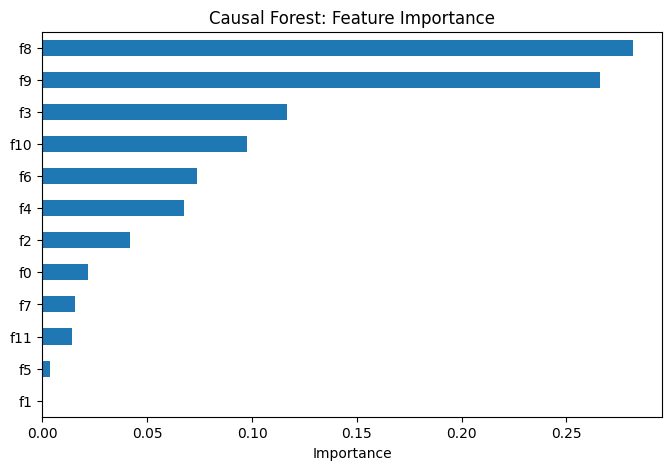

In [21]:
importance = pd.Series(causal_forest.feature_importances_, index=feature_cols).sort_values()

importance.plot.barh(figsize=(8, 5))
plt.xlabel('Importance')
plt.title('Causal Forest: Feature Importance')
plt.show()

**Result:**

- **Tuning:** `min_samples_leaf = 500` had the best validation Qini AUC, but the differences are tiny (0.000445 vs 0.000439 vs 0.000430). So the leaf size doesn't matter much here. The smallest leaf size was best, so smaller leaves might be worth trying.
- **Predictions on the test set:** the mean predicted effect is 0.090 pp, which is very close to the Double ML average effect. The median is only 0.011 pp, and the max is 3.0 pp. So like Double ML, the forest says most customers barely respond and a small group responds a lot.
- The forest's predictions are less extreme than the linear Double ML ones (std 0.27 pp vs 0.48 pp, and the min is only -0.31 pp), so they look more realistic.
- **Confidence intervals:** 15.2% of test customers have an interval entirely above 0, so the forest is fairly confident they respond positively. Only 1.0% have an interval entirely below 0, which is less than the 2.5% I would expect by chance. So there's no evidence that the campaign hurts anyone.
- **Feature importance:** f8 and f9 are by far the most used features (~0.28 and ~0.27), followed by f3, f10, f6 and f4. f1 and f5 are almost never used.
- This mostly agrees with Double ML: f3, f4, f8 and f9 were the significant or close-to-significant features there too. f9 also had the biggest difference between converters and non-converters in my EDA (16.0 vs 36.3).

### Comparing the Models on the Test Set

- First a quick check: I compare the average predicted effect of each model with the actual average effect in the test set, and look at the range of the predictions.

In [22]:
model_cols = ['baseline', 'dml_linear', 'causal_forest']

test_treated = results[results['treatment'] == 1]['conversion'].mean()
test_control = results[results['treatment'] == 0]['conversion'].mean()

print('Observed average effect in the test set:', test_treated - test_control)

results[['dml_linear', 'causal_forest']].describe().T[['mean', 'std', 'min', '50%', 'max']]

Observed average effect in the test set: 0.0011445980799229239


,mean,std,min,50%,max
dml_linear,0.000893,0.004779,-0.008559,-0.000177,0.125322
causal_forest,0.000898,0.002743,-0.003056,0.000109,0.030455


- Next, the metrics with 95% bootstrap confidence intervals, and then the difference from the baseline. If the interval for the difference includes 0, the model isn't clearly different from the baseline.

In [23]:
start = time.time()

boot = bootstrap(results, model_cols)

print('Minutes:', round((time.time() - start) / 60, 1))

ci_table(results, model_cols, boot)

Minutes: 0.5


,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
baseline,"0.0004 [0.0001, 0.0007]","0.0093 [-0.0028, 0.0247]","0.0080 [0.0019, 0.0161]","0.0047 [0.0016, 0.0084]","0.0032 [0.0012, 0.0056]","0.0022 [0.0010, 0.0037]"
dml_linear,"0.0003 [0.0001, 0.0007]","0.0088 [-0.0040, 0.0237]","0.0062 [-0.0007, 0.0137]","0.0042 [0.0011, 0.0082]","0.0035 [0.0015, 0.0062]","0.0022 [0.0010, 0.0038]"
causal_forest,"0.0004 [0.0001, 0.0007]","0.0122 [0.0007, 0.0266]","0.0077 [0.0020, 0.0154]","0.0045 [0.0017, 0.0083]","0.0035 [0.0016, 0.0059]","0.0022 [0.0010, 0.0037]"


In [24]:
diff_table(results, model_cols, boot)

,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
dml_linear,"-0.0000 [-0.0001, 0.0001]","-0.0005 [-0.0044, 0.0039]","-0.0018 [-0.0034, -0.0003]","-0.0005 [-0.0012, 0.0007]","0.0003 [-0.0004, 0.0010]","-0.0000 [-0.0003, 0.0004]"
causal_forest,"0.0000 [-0.0000, 0.0001]","0.0029 [-0.0022, 0.0083]","-0.0004 [-0.0018, 0.0017]","-0.0002 [-0.0007, 0.0006]","0.0003 [-0.0001, 0.0008]","-0.0000 [-0.0002, 0.0002]"


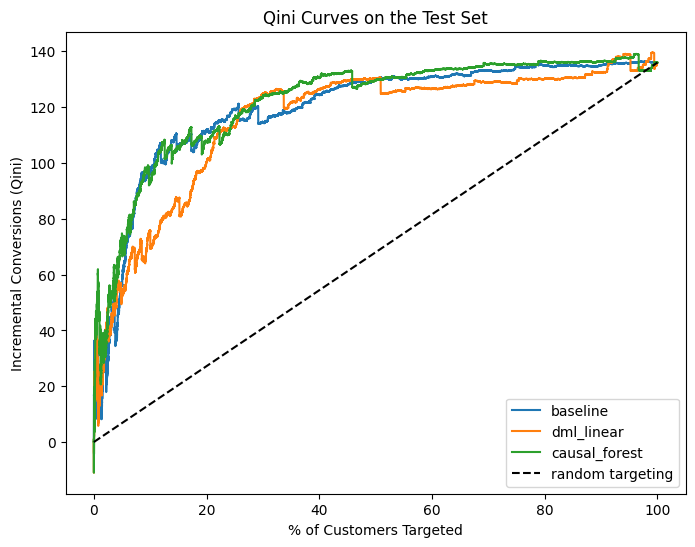

In [25]:
plt.figure(figsize=(8, 6))

for col in model_cols:
    curve = uplift_curve(results, col)
    plt.plot(curve['pct_targeted'] * 100, curve['qini'], label=col)

# random targeting line
last_qini = uplift_curve(results, 'baseline')['qini'].iloc[-1]
plt.plot([0, 100], [0, last_qini], 'k--', label='random targeting')

plt.xlabel('% of Customers Targeted')
plt.ylabel('Incremental Conversions (Qini)')
plt.title('Qini Curves on the Test Set')
plt.legend()
plt.show()

**Result:**

**Sanity check**

- The observed average effect in the test set is 0.114 pp. Double ML (0.089 pp) and the causal forest (0.090 pp) are a bit lower, but that's within the noise, and it's close to the Double ML average effect (0.081 pp).
- Both models give realistic predictions (between -0.9 pp and +12.5 pp). For comparison, the T-learner in `Modeling_sample_2.ipynb` predicts effects from -67.5 pp to +68.7 pp, because its control model only had 127 conversions to learn from.

**Metrics**

- **Qini AUC:** the baseline and the causal forest are tied (0.0004). Double ML is slightly lower (0.0003).
- **Top 5%:** the causal forest (1.22 pp) is the only model whose interval is above 0. The baseline is 0.93 pp, but its interval includes 0.
- **Top 50%:** all three models have an uplift of about 0.22 pp. That's about **twice** the average effect (0.114 pp), so targeting the top half with any of these models roughly doubles the effect per customer targeted.

**Difference from the baseline**

- Almost all of the intervals include 0, so **none of the new models is clearly better than the baseline**.
- The only clear difference is that Double ML is **worse** than the baseline in the top 10% (-0.18 pp, CI [-0.34, -0.03]).
- The causal forest is ahead of the baseline in the top 5% (+0.29 pp) and the top 30% (+0.03 pp), but these intervals include 0, so it could be chance.

**Qini curves**

- All the models are well above the random targeting line, so using any of them is better than targeting at random.
- The baseline and the causal forest are almost on top of each other, with the causal forest a little higher between about 30% and 50%.
- Double ML is below them between about 5% and 30%, and only catches up after that.
- Most of the incremental conversions (about 130 of about 136) come from the top 40-50% of customers, so targeting the bottom half adds almost nothing.
- The curves are very jumpy because there are only 42 control conversions in the test set.

**Overall**

- All three methods agree that the campaign increases conversion by about 0.08 to 0.11 pp (roughly a 40-55% relative lift).
- The causal forest is the best of the causal models, but it only ties the baseline. The baseline just ranks customers by how likely they are to convert if treated, which suggests that the customers who are most likely to convert are also the ones who respond most to the campaign.
- With only 42 control conversions in the test set, the intervals are wide. The next step is to run the causal forest and the baseline on the full dataset to see if the causal forest's small lead in the top 5% holds up (see `Causal_Forest_DML_PSM_full.ipynb`).

### Saving the Scores

- I save the Double ML and causal forest scores for the test customers, in the same order as the test set in `Modeling_sample_2.ipynb`.
- To add them to the comparison there, I run the cell below in `Modeling_sample_2.ipynb` after its `results` table is created. The `assert` lines give an error if the customers aren't the same.

```python
new_scores = pd.read_parquet('causal_model_scores.parquet')

assert (new_scores['treatment'].to_numpy() == results['treatment'].to_numpy()).all()
assert (new_scores['conversion'].to_numpy() == results['conversion'].to_numpy()).all()

results['dml_linear'] = new_scores['dml_linear'].to_numpy()
results['causal_forest'] = new_scores['causal_forest'].to_numpy()

model_columns = model_columns + ['dml_linear', 'causal_forest']
```

In [26]:
results[['treatment', 'conversion', 'dml_linear', 'causal_forest']].to_parquet('causal_model_scores.parquet', index=False)

(ate * 100).round(4).to_csv('average_effect_estimates.csv')

print('Saved causal_model_scores.parquet and average_effect_estimates.csv')

Saved causal_model_scores.parquet and average_effect_estimates.csv
